##### 1. Precios
¿Cuánto cuesta la vivienda en España, cuánto ha subido y dónde?

Para ello usaremos:

- Valor tasado de la vivienda libre (MITMA), vivienda total, 2007-2025.
- Precios en €/m² nominales y en euros constantes de 2025 (IPC base 2025).
- 2026 queda fuera: solo tiene dos trimestres publicados.


In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# El import de src/ funciona tanto si Jupyter se lanza desde la raíz del
# proyecto como desde notebooks/.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import FIGURES_DIR, NATIONAL_CODE, PROCESSED_DIR  # noqa: E402

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 150,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Sin dtype, "04" se convierte en 4 y "00" en 0: el cruce por provincia deja
# de casar. Se lee siempre con el código como texto.
panel = pd.read_csv(
    PROCESSED_DIR / "panel_provincia_anual.csv",
    dtype={"province_code": str},
)

In [4]:
national = (
    panel.loc[(panel["province_code"] == NATIONAL_CODE) & (panel["kind"] == "total")]
    .sort_values("year")
    .reset_index(drop=True)
)

national[["year", "price_nominal_eur_m2", "price_real_eur_m2"]].tail(3)

,year,price_nominal_eur_m2,price_real_eur_m2
16,2023,1809.08,1908.96
17,2024,1913.62,1964.76
18,2025,2127.57,2127.57


##### La figura

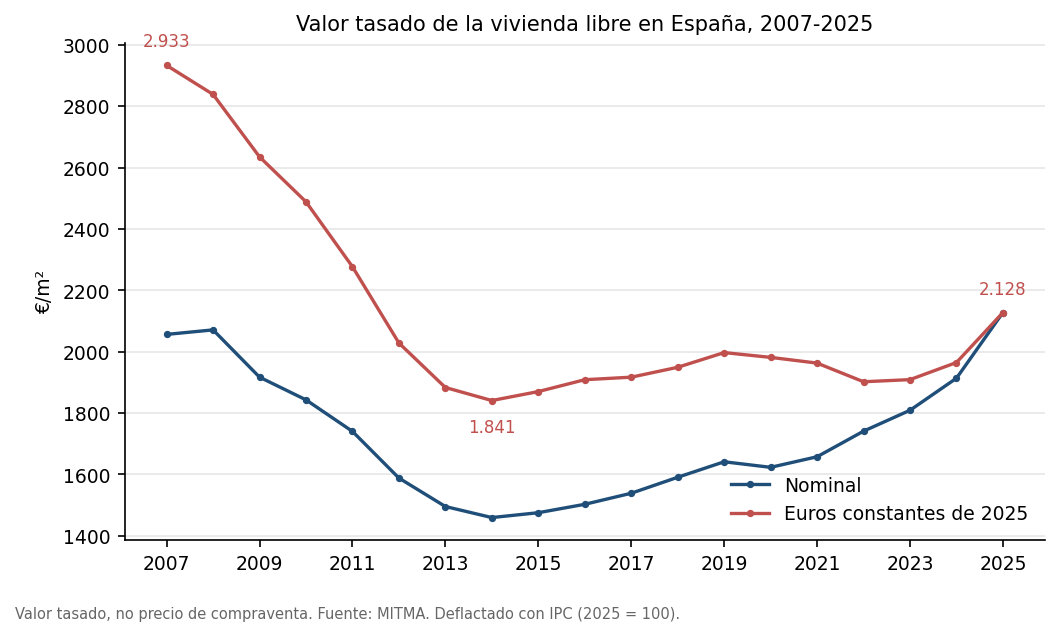

In [6]:
def eur(value):
    return f"{value:,.0f}".replace(",", ".")

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    national["year"], national["price_nominal_eur_m2"],
    marker="o", markersize=2.5, linewidth=1.6,
    color="#1f4e79", label ="Nominal",
    )

ax.plot(
    national["year"], national["price_real_eur_m2"],
    marker="o", markersize=2.5, linewidth=1.6,
    color="#c0504d", label="Euros constantes de 2025",
)

ax.set_title("Valor tasado de la vivienda libre en España, 2007-2025")
ax.set_ylabel("€/m²")
ax.set_xticks(range(2007,2026, 2))
ax.grid(axis="y", color = "0.9", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")

peak = national.loc[national["price_real_eur_m2"].idxmax()]
trough = national.loc[national["price_real_eur_m2"].idxmin()]
last = national.iloc[-1]

for row, dy in ((peak, 9), (trough, -15), (last, 9)):
    ax.annotate(
        eur(row["price_real_eur_m2"]),
        (row["year"], row["price_real_eur_m2"]),
        textcoords="offset points", xytext=(0, dy),
        ha="center", fontsize=8, color="#c0504d",
    )

fig.text(
    0.0, -0.04,
    "Valor tasado, no precio de compraventa. Fuente: MITMA. "
    "Deflactado con IPC (2025 = 100).",
    fontsize=7, color="0.4",
)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_nacional_nominal_real.png", bbox_inches="tight")
plt.show()